<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/mathematical_biology/mathbio_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Mathematical Biology* — `mathbio_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# MathBio Ch 4 Figures — Colab Notebook
**Mathematical Biology · Chapter 4: Random Variations**

PSE Lab · SeoulTech · Tong (Cambridge)

Figures saved to `figures/ch04/`. Run each cell independently.

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | Birth-death: $p_n(t)$, extinction prob., stochastic trajectories | §4.1 |
| fig02 | Fokker-Planck: spreading, Boltzmann steady state, $\langle x\rangle$, $\sigma$ | §4.2 |
| fig03 | Langevin trajectories, $D=k_BT/\gamma$, Poisson gene noise | §4.2–4.3 |
| fig04 | Stochastic SIR, epidemic probability, demographic vs environmental noise | §4 |
| fig05 | Generating function, Kramers-Moyal, van Kampen $\Omega^{-1/2}$ | §4.1–4.2 |

---
## fig01 · Birth-Death Process (§4.1)

**Left**: Master equation — $p_n(t)$ evolving from $n_0=5$. **Right**: Extinction probability $p_{\rm ext}=\delta/\beta$ vs birth rate. **Far right**: Stochastic trajectories vs deterministic exponential growth.

  saved -> figures/ch04/fig01_birth_death.png


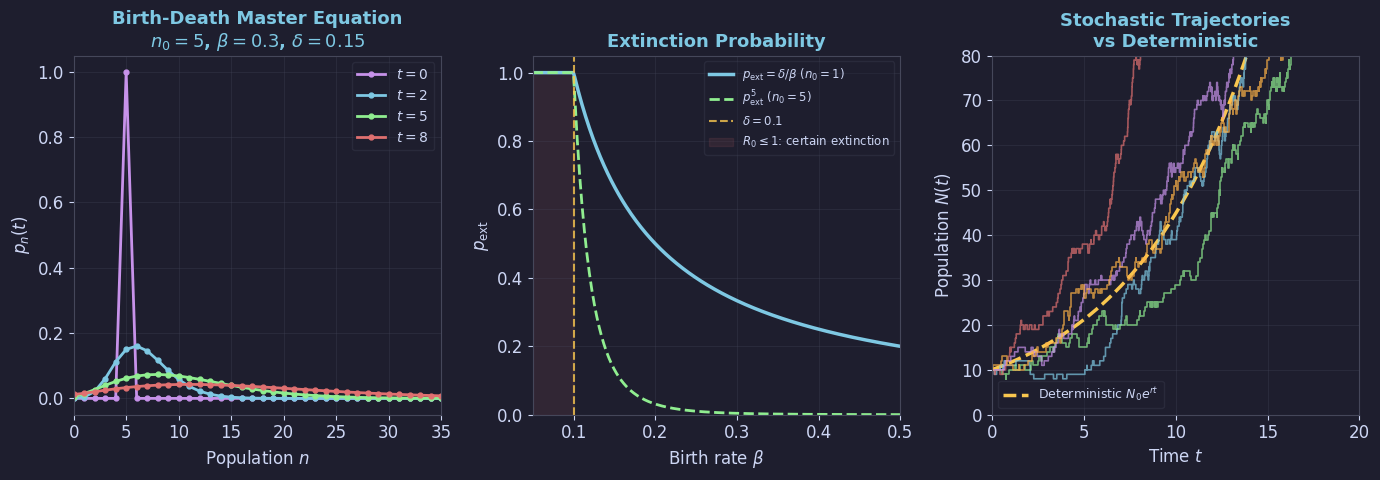

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid
from scipy.stats import poisson
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01: Birth-Death master equation + extinction (§4.1) ────────────────
N_max=40; beta_m=0.3; delta_m=0.15
p=np.zeros(N_max+1); p[5]=1.0
dt_m=0.05; p_snaps={0:p.copy()}; t_m=0.0
while t_m<8.0:
    dp=np.zeros_like(p)
    for n in range(N_max+1):
        dp[n]=(beta_m*(n-1)*p[n-1] if n>0 else 0)
        dp[n]+=(delta_m*(n+1)*p[n+1] if n<N_max else 0)
        dp[n]-=(beta_m+delta_m)*n*p[n]
    p=np.maximum(p+dt_m*dp,0); s=p.sum(); p=p/s if s>0 else p
    t_m+=dt_m
    for tgt in [2,5,8]:
        if tgt not in p_snaps and abs(t_m-tgt)<dt_m*0.6:
            p_snaps[tgt]=p.copy()

fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)
n_arr=np.arange(N_max+1)
ax=axes[0]
for t_t,col,lab in [(0,PURPLE,'$t=0$'),(2,BLUE,'$t=2$'),(5,GREEN,'$t=5$'),(8,RED,'$t=8$')]:
    ax.plot(n_arr,p_snaps[t_t],color=col,lw=2.0,marker='o',ms=3.5,label=lab)
ax.set_xlabel('Population $n$'); ax.set_ylabel('$p_n(t)$')
ax.set_title('Birth-Death Master Equation\n$n_0=5$, $\\beta=0.3$, $\\delta=0.15$',color=BLUE)
ax.legend(fontsize=10,labelcolor=FG); ax.grid(True); ax.set_xlim(0,35)

beta_arr=np.linspace(0.05,0.5,300); delta=0.1
p_ext=np.where(beta_arr>delta,delta/beta_arr,1.0)
ax2=axes[1]
ax2.plot(beta_arr,p_ext,color=BLUE,lw=2.5,label=r'$p_{\rm ext}=\delta/\beta$ ($n_0=1$)')
ax2.plot(beta_arr,p_ext**5,color=GREEN,lw=2.0,ls='--',label=r'$p_{\rm ext}^5$ ($n_0=5$)')
ax2.axvline(delta,color=YELLOW,lw=1.5,ls='--',alpha=0.8,label=f'$\\delta={delta}$')
ax2.fill_between(beta_arr[beta_arr<=delta],0,1,color=RED,alpha=0.1,label='$R_0\\leq1$: certain extinction')
ax2.set_xlabel(r'Birth rate $\beta$'); ax2.set_ylabel(r'$p_{\rm ext}$')
ax2.set_title('Extinction Probability',color=BLUE)
ax2.legend(fontsize=8.5,labelcolor=FG); ax2.grid(True); ax2.set_xlim(0.05,0.5); ax2.set_ylim(0,1.05)

np.random.seed(42); beta_s=0.3; delta_s=0.15; N0=10
t_det=np.linspace(0,20,300); N_det=N0*np.exp((beta_s-delta_s)*t_det)
ax3=axes[2]
ax3.plot(t_det,N_det,color=YELLOW,lw=2.5,ls='--',label='Deterministic $N_0e^{rt}$')
for trial,col in enumerate([BLUE,GREEN,RED,PURPLE,ORANGE]):
    np.random.seed(trial*7)
    N_t=N0; t_now=0; t_list=[0]; N_list=[N0]
    while t_now<20 and N_t>0:
        rt=(beta_s+delta_s)*N_t
        t_now-=np.log(np.random.rand())/rt
        if np.random.rand()<beta_s/(beta_s+delta_s): N_t+=1
        else: N_t-=1
        t_list.append(t_now); N_list.append(N_t)
    ax3.step(t_list,N_list,where='post',color=col,lw=1.2,alpha=0.7)
ax3.set_xlabel('Time $t$'); ax3.set_ylabel('Population $N(t)$')
ax3.set_title('Stochastic Trajectories\nvs Deterministic',color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True); ax3.set_xlim(0,20); ax3.set_ylim(0,80)
plt.tight_layout(pad=1.2)
save('fig01_birth_death.png',fig)


---
## fig02 · Fokker-Planck Equation (§4.2)

**Left**: Gaussian spreading with drift — $P(x,t)$ at successive times. **Centre**: Steady-state Boltzmann distribution $P_{ss}\propto e^{-V(x)/D}$ for harmonic potential. **Right**: Mean $\langle x\rangle=vt$ and width $\sigma=\sqrt{2Dt}$.

  saved -> figures/ch04/fig02_fokker_planck.png


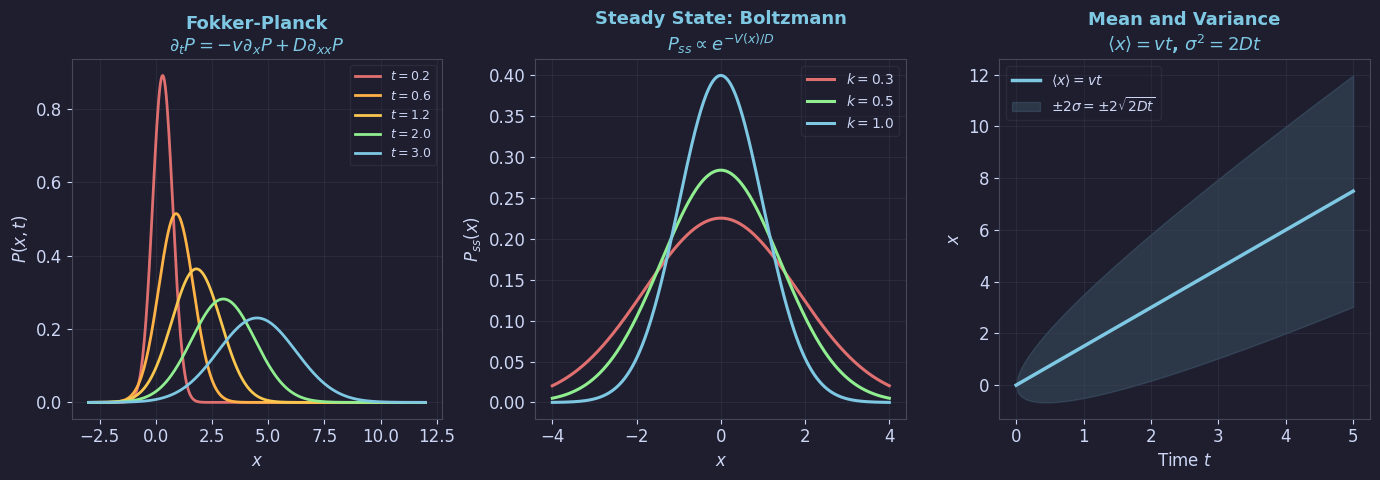

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid
from scipy.stats import poisson
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02: Fokker-Planck — drift+diffusion + steady state (§4.2) ──────────
fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)
x_fp=np.linspace(-3,12,400); v=1.5; D=0.5
ax=axes[0]
for t_val,col,lab in [(0.2,RED,'$t=0.2$'),(0.6,ORANGE,'$t=0.6$'),
                       (1.2,YELLOW,'$t=1.2$'),(2.0,GREEN,'$t=2.0$'),(3.0,BLUE,'$t=3.0$')]:
    m=v*t_val; var=2*D*t_val
    ax.plot(x_fp,np.exp(-(x_fp-m)**2/(2*var))/np.sqrt(2*np.pi*var),color=col,lw=2.0,label=lab)
ax.set_xlabel('$x$'); ax.set_ylabel('$P(x,t)$')
ax.set_title('Fokker-Planck\n'+r'$\partial_t P=-v\partial_xP+D\partial_{xx}P$',color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True)

x_ss=np.linspace(-4,4,400)
ax2=axes[1]
for k_v,col,lab in [(0.3,RED,'$k=0.3$'),(0.5,GREEN,'$k=0.5$'),(1.0,BLUE,'$k=1.0$')]:
    P_ss=np.exp(-0.5*k_v*x_ss**2); P_ss/=trapezoid(P_ss,x_ss)
    ax2.plot(x_ss,P_ss,color=col,lw=2.2,label=f'$k={k_v}$')
ax2.set_xlabel('$x$'); ax2.set_ylabel('$P_{ss}(x)$')
ax2.set_title('Steady State: Boltzmann\n'+r'$P_{ss}\propto e^{-V(x)/D}$',color=BLUE)
ax2.legend(fontsize=10,labelcolor=FG); ax2.grid(True)

t_arr=np.linspace(0,5,200)
ax3=axes[2]
ax3.plot(t_arr,v*t_arr,color=BLUE,lw=2.5,label=r'$\langle x\rangle=vt$')
ax3.fill_between(t_arr,v*t_arr-2*np.sqrt(2*D*t_arr),v*t_arr+2*np.sqrt(2*D*t_arr),
                 color=BLUE,alpha=0.15,label=r'$\pm2\sigma=\pm2\sqrt{2Dt}$')
ax3.set_xlabel('Time $t$'); ax3.set_ylabel('$x$')
ax3.set_title('Mean and Variance\n'+r'$\langle x\rangle=vt$, $\sigma^2=2Dt$',color=BLUE)
ax3.legend(fontsize=10,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig02_fokker_planck.png',fig)


---
## fig03 · Langevin + Fluctuation-Dissipation (§4.2–4.3)

**Left**: Five Langevin trajectories — overdamped particle in harmonic potential. **Centre**: $D=k_BT/\gamma$ — diffusion proportional to temperature, inversely to friction. **Right**: Poisson gene expression noise.

  saved -> figures/ch04/fig03_langevin.png


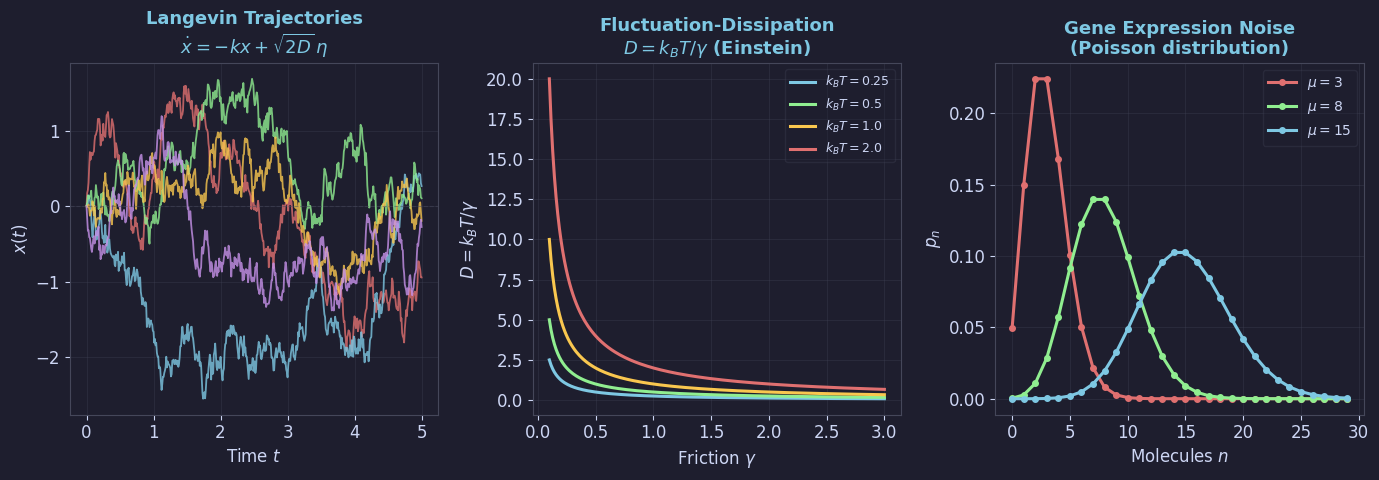

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid
from scipy.stats import poisson
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03: Langevin + fluctuation-dissipation + gene noise (§4.2-4.3) ─────
fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)
np.random.seed(0); dt_L=0.01; N_steps=500; t_L=np.linspace(0,5,N_steps+1)
ax=axes[0]
for i,col in enumerate([RED,BLUE,GREEN,YELLOW,PURPLE]):
    x_L=np.zeros(N_steps+1)
    for j in range(N_steps):
        x_L[j+1]=x_L[j]+dt_L*(-0.5*x_L[j])+np.sqrt(2*0.5*dt_L)*np.random.randn()
    ax.plot(t_L,x_L,color=col,lw=1.3,alpha=0.8)
ax.axhline(0,color=EDGE,lw=0.8,ls='--',alpha=0.5)
ax.set_xlabel('Time $t$'); ax.set_ylabel('$x(t)$')
ax.set_title('Langevin Trajectories\n'+r'$\dot x=-kx+\sqrt{2D}\,\eta$',color=BLUE); ax.grid(True)

gamma_arr=np.linspace(0.1,3,200)
ax2=axes[1]
for kBT_v,col,lab in [(0.25,BLUE,'$k_BT=0.25$'),(0.5,GREEN,'$k_BT=0.5$'),
                       (1.0,YELLOW,'$k_BT=1.0$'),(2.0,RED,'$k_BT=2.0$')]:
    ax2.plot(gamma_arr,kBT_v/gamma_arr,color=col,lw=2.2,label=lab)
ax2.set_xlabel('Friction $\\gamma$'); ax2.set_ylabel('$D=k_BT/\\gamma$')
ax2.set_title('Fluctuation-Dissipation\n'+r'$D=k_BT/\gamma$ (Einstein)',color=BLUE)
ax2.legend(fontsize=9,labelcolor=FG); ax2.grid(True)

n_mol=np.arange(0,30)
ax3=axes[2]
for mu,col,lab in [(3,RED,'$\\mu=3$'),(8,GREEN,'$\\mu=8$'),(15,BLUE,'$\\mu=15$')]:
    ax3.plot(n_mol,poisson.pmf(n_mol,mu),color=col,lw=2.2,marker='o',ms=4,label=lab)
ax3.set_xlabel('Molecules $n$'); ax3.set_ylabel('$p_n$')
ax3.set_title('Gene Expression Noise\n(Poisson distribution)',color=BLUE)
ax3.legend(fontsize=10,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig03_langevin.png',fig)


---
## fig04 · Stochastic SIR + Noise Scaling (§4)

**Left**: Stochastic SIR ($N=200$) — individual realisations vs deterministic. **Centre**: Epidemic probability $P=1-1/R_0$ from branching process. **Right**: Demographic CV$\sim N^{-1/2}$ vs environmental noise.

  saved -> figures/ch04/fig04_stochastic_sir.png


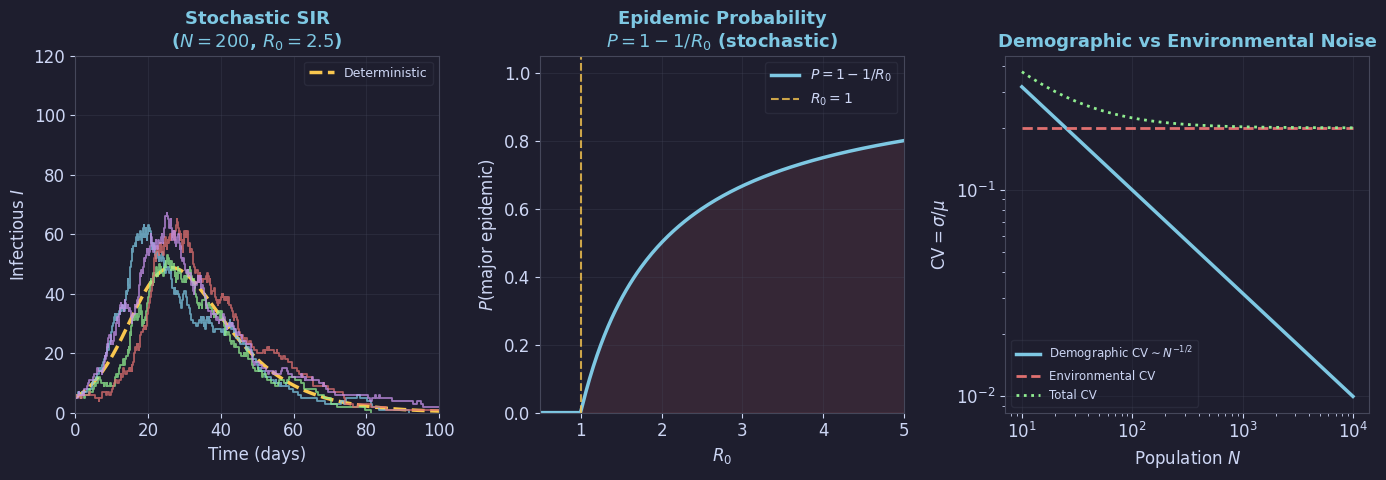

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid
from scipy.stats import poisson
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04: Stochastic SIR + epidemic probability + noise scaling (§4) ─────
fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)
def sir_det(t,y): S,I,R=y; return [-0.25*S*I/200,0.25*S*I/200-0.1*I,0.1*I]
ax=axes[0]
sol=solve_ivp(sir_det,[0,100],[195,5,0],max_step=0.5,dense_output=True)
t_d=np.linspace(0,100,500); tr=sol.sol(t_d)
ax.plot(t_d,tr[1],color=YELLOW,lw=2.5,ls='--',label='Deterministic')
np.random.seed(3)
for trial,col in enumerate([BLUE,GREEN,RED,PURPLE]):
    S,I,R=195,5,0; t_now=0; t_list=[0]; I_list=[I]
    while t_now<100 and I>0:
        r1=0.25*S*I/200; r2=0.1*I; rt=r1+r2
        if rt==0: break
        t_now-=np.log(np.random.rand())/rt
        if np.random.rand()<r1/rt: S-=1; I+=1
        else: I-=1; R+=1
        t_list.append(t_now); I_list.append(I)
    ax.step(t_list,I_list,where='post',color=col,lw=1.3,alpha=0.75)
ax.set_xlabel('Time (days)'); ax.set_ylabel('Infectious $I$')
ax.set_title('Stochastic SIR\n($N=200$, $R_0=2.5$)',color=BLUE)
ax.legend(fontsize=9,labelcolor=FG); ax.grid(True); ax.set_xlim(0,100); ax.set_ylim(0,120)

R0_arr2=np.linspace(0.5,5,200)
ax2=axes[1]
ax2.plot(R0_arr2,np.where(R0_arr2>1,1-1/R0_arr2,0),color=BLUE,lw=2.5,label='$P=1-1/R_0$')
ax2.axvline(1,color=YELLOW,lw=1.5,ls='--',alpha=0.8,label='$R_0=1$')
ax2.fill_between(R0_arr2,np.where(R0_arr2>1,1-1/R0_arr2,0),0,
                 where=(R0_arr2>1),color=RED,alpha=0.12)
ax2.set_xlabel('$R_0$'); ax2.set_ylabel('$P$(major epidemic)')
ax2.set_title('Epidemic Probability\n$P=1-1/R_0$ (stochastic)',color=BLUE)
ax2.legend(fontsize=10,labelcolor=FG); ax2.grid(True); ax2.set_xlim(0.5,5); ax2.set_ylim(0,1.05)

N_pop=np.logspace(1,4,200)
ax3=axes[2]
ax3.loglog(N_pop,1/np.sqrt(N_pop),color=BLUE,lw=2.5,label=r'Demographic CV$\sim N^{-1/2}$')
ax3.loglog(N_pop,0.2*np.ones_like(N_pop),color=RED,lw=2.0,ls='--',label='Environmental CV')
ax3.loglog(N_pop,np.sqrt(1/N_pop+0.04),color=GREEN,lw=2.0,ls=':',label='Total CV')
ax3.set_xlabel('Population $N$'); ax3.set_ylabel('CV$=\\sigma/\\mu$')
ax3.set_title('Demographic vs Environmental Noise',color=BLUE)
ax3.legend(fontsize=8.5,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig04_stochastic_sir.png',fig)


---
## fig05 · Generating Function + Kramers-Moyal + van Kampen (§4.1–4.2)

**Left**: Generating function $G(z,t)$ for birth-death process. **Centre**: Kramers-Moyal moments $A(n)$ (drift) and $B(n)$ (diffusion). **Right**: van Kampen $\Omega^{-1/2}$ scaling of fluctuations.

  saved -> figures/ch04/fig05_generating_fn.png


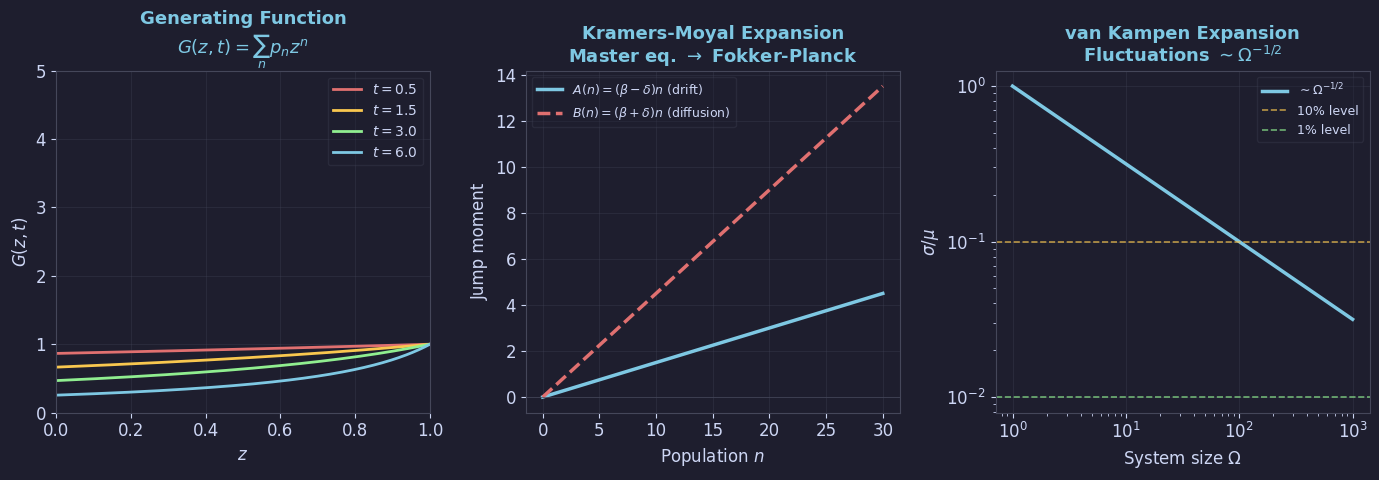

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid
from scipy.stats import poisson
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch04'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05: Generating function + Kramers-Moyal + van Kampen (§4.1-4.2) ────
fig,axes=plt.subplots(1,3,figsize=(14,5)); fig.patch.set_facecolor(BG)
z_arr=np.linspace(0,1,300); beta_g=0.3; delta_g=0.15
ax=axes[0]
for t_v,col,lab in [(0.5,RED,'$t=0.5$'),(1.5,YELLOW,'$t=1.5$'),
                     (3.0,GREEN,'$t=3.0$'),(6.0,BLUE,'$t=6.0$')]:
    p_t=np.clip((beta_g*(np.exp((beta_g-delta_g)*t_v)-1)/
                 (beta_g*np.exp((beta_g-delta_g)*t_v)-delta_g)),0,0.9999)
    ax.plot(z_arr,np.clip((1-p_t)/(1-p_t*z_arr),0,5),color=col,lw=2.0,label=f'$t={t_v}$')
ax.set_xlabel('$z$'); ax.set_ylabel('$G(z,t)$')
ax.set_title('Generating Function\n$G(z,t)=\\sum_n p_n z^n$',color=BLUE)
ax.legend(fontsize=10,labelcolor=FG); ax.grid(True); ax.set_xlim(0,1); ax.set_ylim(0,5)

n_arr2=np.linspace(0,30,200)
ax2=axes[1]
ax2.plot(n_arr2,0.15*n_arr2,color=BLUE,lw=2.5,label=r'$A(n)=(\beta-\delta)n$ (drift)')
ax2.plot(n_arr2,0.45*n_arr2,color=RED,lw=2.5,ls='--',label=r'$B(n)=(\beta+\delta)n$ (diffusion)')
ax2.axhline(0,color=EDGE,lw=0.5)
ax2.set_xlabel('Population $n$'); ax2.set_ylabel('Jump moment')
ax2.set_title('Kramers-Moyal Expansion\nMaster eq. $\\to$ Fokker-Planck',color=BLUE)
ax2.legend(fontsize=9,labelcolor=FG); ax2.grid(True)

Omega_arr=np.logspace(0,3,200)
ax3=axes[2]
ax3.loglog(Omega_arr,1/np.sqrt(Omega_arr),color=BLUE,lw=2.5,label=r'$\sim\Omega^{-1/2}$')
ax3.axhline(0.1,color=YELLOW,lw=1.2,ls='--',alpha=0.7,label='10% level')
ax3.axhline(0.01,color=GREEN,lw=1.2,ls='--',alpha=0.7,label='1% level')
ax3.set_xlabel('System size $\\Omega$'); ax3.set_ylabel('$\\sigma/\\mu$')
ax3.set_title('van Kampen Expansion\n'+r'Fluctuations $\sim\Omega^{-1/2}$',color=BLUE)
ax3.legend(fontsize=9,labelcolor=FG); ax3.grid(True)
plt.tight_layout(pad=1.2)
save('fig05_generating_fn.png',fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/ch04'
saved=sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved: print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name='mathbio_ch04_figures.zip'
with zipfile.ZipFile(zip_name,'w',zipfile.ZIP_DEFLATED) as zf:
    for fname in saved: zf.write(f'{OUTDIR}/{fname}',arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 5 figures:
  fig01_birth_death.png  (207 KB)
  fig02_fokker_planck.png  (225 KB)
  fig03_langevin.png  (308 KB)
  fig04_stochastic_sir.png  (190 KB)
  fig05_generating_fn.png  (157 KB)
Zip: mathbio_ch04_figures.zip  (1037 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>